<style>
@media print { @page {size:A4; margin:13mm 15mm;} .pagebreak {break-before:page;} }
body {font-family:Arial,sans-serif;} .jp-RenderedHTMLCommon {font-size:12px;line-height:1.35;}
h1 {font-size:23px!important;} h2 {font-size:18px!important;} h3 {font-size:15px!important;}
table {font-size:11px!important;} 
.jp-Cell {padding:2px 0!important;} img {max-width:100%;} 
</style>
# Кто снизил активность и кого включить в кампанию
Банк «Меридиан» · набор S31 · данные синтетические · 09.11.2026


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from IPython.display import display
clean = pd.read_csv("results/clean_clients_metrics.csv", dtype={"client_id": "string"})
trend = pd.read_csv("results/trend.csv", index_col=0)
groups = pd.read_csv("results/group_summary.csv", index_col=0)
channels = pd.read_csv("results/breakdown_channel.csv", index_col=0)
exclusions = pd.read_csv("results/exclusions.csv")
log = pd.read_csv("cleaning_log.csv")
campaign = pd.read_csv("campaign_list.csv")
assert len(campaign) == 1924 and campaign.client_id.is_unique
assert groups.n_clients.tolist() == [1454, 280, 190]
plt.rcParams.update({"font.size": 10, "figure.dpi": 100})


## 1. Главное
- В постоянной когорте число успешных операций в месяц снизилось на **18.51%**: сравниваем 2024 год с январём–июнем 2025. При сравнении одинаковых полугодий падение **11.61%** сохраняется.
- Массовый сегмент с ненулевой базой снизил активность на **32,71%** (n=2674), зарплатный — на **7,90%** (n=1517).
- Предлагаем **1924 клиента в трёх группах: 1454 / 280 / 190**. Все дали согласие на маркетинг; повторов нет.
- Токен в целом вырос на **30,71%**, но у отдельных клиентов снизился. Общий рост канала не исключает индивидуального ухода.

## 2. Контекст
Нужно вернуть активность с бюджетом до 2000 клиентов. Выбираем три группы по каналу, который дал наибольшую потерю операций у клиента. Предлагаемые сообщения — гипотезы для теста, а не доказанный способ возврата.

## 3. Данные и ограничения
Выгрузка: 5696 строк справочника и 613095 строк операций. После объединения версий — **5641 уникальный клиент**. Для сравнения используется постоянная когорта зарегистрированных до 01.01.2024; новые клиенты не получают искусственного сравнения с неполной базой.

**Метрика:** успешные положительные операции за период / число календарных месяцев (12 и 6). Учитываем все каналы и валюты, включая месяцы с нулём. Метрика отражает частоту пользования, но не видит падения суммы покупок, среднего чека и доходности. Суммы разных валют не складываем.

Справочник — срез действующих клиентов на 30.06.2025: ушедшие клиенты могут отсутствовать. Нет причин отказа от продукта, данных других банков, условий тарифов, истории сегментов и отклика на кампании. Наблюдаемое падение в канале не доказывает причину поведения.


<div class="pagebreak"></div>

## 4. Находки
### Падение сохраняется при сравнении одинаковых полугодий

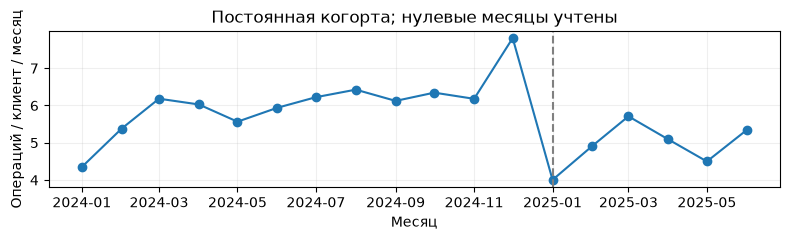

In [2]:
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.plot(pd.to_datetime(trend.index), trend.operations_per_cohort_client, marker="o")
ax.axvline(pd.Timestamp("2025-01-01"), color="gray", linestyle="--")
ax.set(xlabel="Месяц", ylabel="Операций / клиент / месяц", title="Постоянная когорта; нулевые месяцы учтены")
ax.grid(alpha=.2)
plt.tight_layout(); plt.show()


Период: январь 2024 — июнь 2025. Размер постоянной когорты: **5497 клиентов**. Сравнение 2024 H1 и 2025 H1 уменьшает оценку падения с 18,51% до 11,61%: сезонность влияет на величину, но не отменяет направление.

### Оплаты токеном растут, остальные каналы снижаются

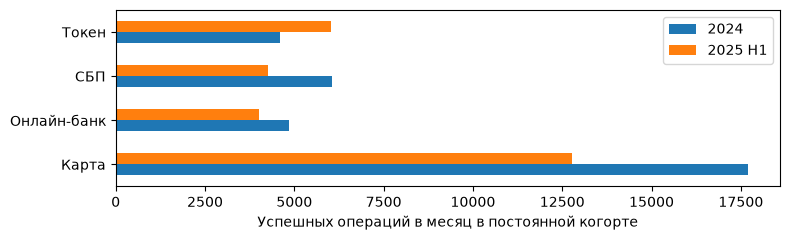

In [3]:
fig, ax = plt.subplots(figsize=(8, 2.5))
channels[["base_per_month", "current_per_month"]].plot.barh(ax=ax)
ax.set(xlabel="Успешных операций в месяц в постоянной когорте", ylabel="")
ax.legend(["2024", "2025 H1"])
plt.tight_layout(); plt.show()


Пластиковая карта: −27,87%, СБП: −29,56%, онлайн-банк: −17,21%, токен: +30,71%. Это разложение изменения по каналам, а не доказательство перетока одних и тех же клиентов. Смена канала без общего снижения не является основанием включить клиента в кампанию.

<div class="pagebreak"></div>

## 5. Группы для кампании
Общие условия: регистрация до 01.01.2024, ненулевая базовая активность, согласие «Да», общее падение не менее 20% **и** не менее одной операции в месяц. Канал группы использовался в базе и дал наибольшую абсолютную потерю операций в месяц среди четырёх каналов.


,Клиентов,Операций/мес. до,Операций/мес. после,"Падение, %"
group,,,,
G1_Карта,1454,6.80,3.30,51.52
G2_СБП,280,6.69,3.66,45.34
G3_Токен,190,7.36,3.56,51.65


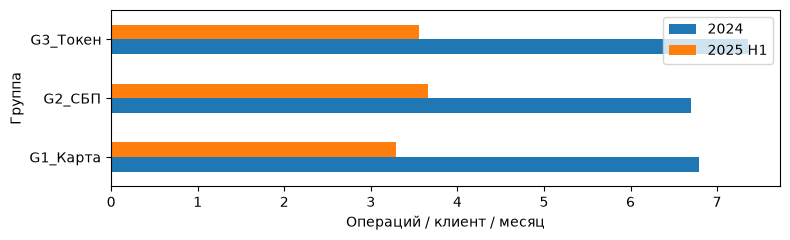

In [4]:
table = groups[["n_clients", "base_mean", "current_mean", "aggregate_drop_pct"]].round(2)
table.columns = ["Клиентов", "Операций/мес. до", "Операций/мес. после", "Падение, %"]
display(table)
fig, ax = plt.subplots(figsize=(8, 2.5))
groups[["base_mean", "current_mean"]].plot.barh(ax=ax)
ax.set(xlabel="Операций / клиент / месяц", ylabel="Группа")
ax.legend(["2024", "2025 H1"])
plt.tight_layout(); plt.show()


**G1 — Карта, 1454 клиента.** Основная потеря пришлась на оплату пластиком: 3710,58 операции в месяц из общей потери группы 5091,33. Предложение: проверить удобство использования карты и протестировать стимул к оплате пластиком.

**G2 — СБП, 280 клиентов.** Основная потеря в СБП: 591,67 операции в месяц из 849,83. Предложение: напоминание о сценариях оплаты СБП и короткий опрос о препятствиях.

**G3 — Токен, 190 клиентов.** Основная потеря в токене: 423,17 операции в месяц из 722,25. Предложение: помощь с настройкой оплаты смартфоном и проверка технических затруднений.

У **1908 из 1924** отобранных клиентов снизилось несколько каналов. Для единственного назначения берём максимальную потерю; при равенстве порядок: Карта → СБП → Токен → Онлайн-банк. Поэтому разрезы пересекаются, итоговые группы — нет. Потеря ведущего канала не обязана объяснять всю потерю клиента.

Ожидаемый эффект и экономическая выгода неизвестны. Начать с тестовой кампании и контрольной группы; это рекомендация следующего этапа, а не выполненный эксперимент.


<div class="pagebreak"></div>

## 6. Кого не включаем и почему
Причины ниже взаимоисключающие: применяется первая подходящая причина сверху в порядке методики. Знаменатель — 5641 клиент справочника.


In [5]:
display(exclusions.rename(columns={"reason": "Причина / результат", "n_clients": "Клиентов"}))

,Причина / результат,Клиентов
0,Нет падения >=20% и >=1 операции/месяц,2497
1,В кампании,1924
2,Нет согласия,687
3,Нет активности в базе,276
4,Основная потеря в Онлайн-банке или лимит,136
5,Неполный/неизвестный базовый период,121


136 подходящих по общему падению клиентов имеют ведущую потерю в онлайн-банке. Отдельная группа не достигает минимума 150; произвольно присоединять её к другому каналу нельзя. Все 1924 клиента трёх выбранных групп укладываются в бюджет, поэтому обрезать список не пришлось.

Операции без справочной записи (30265 строк сырой выгрузки, 359 ID) не участвуют в анализе кампании: неизвестны признаки и согласие. Это отдельное ограничение, не дополнительные клиенты к знаменателю 5641.

## 7. Что проверили и что не подтвердилось
- **«Все каналы падают».** Нет: число операций токеном в постоянной когорте выросло на 30,71%.
- **«Сегменты падают одинаково».** Нет: массовый −32,71% (n=2674), зарплатный −7,90% (n=1517), среди сопоставимых клиентов с ненулевой базой.
- **«Падение исчезнет при сравнении одинаковых полугодий».** Нет: снижение составляет 11,61%.
- **«Результат определяется крупными суммами».** После исключения верхнего 1% сумм RUB снижение числа операций 18,45% вместо 18,51%. Это проверка устойчивости, не основной фильтр.

Все проценты изменения сравнивают операции в расчёте на месяц. Различия описательные, статистическая значимость и причинность не заявляются.

Дополнительно: среди 4817 клиентов с картой до 2024 года падение составляет 21,27%. Позднее открытие карты влияет на оценку общей динамики, но у всех 1924 участников кампании карта уже была открыта до 2024 года. У участников доля отказов среди попыток (без возвратов) выросла с 1,90% (3054/160913) до 2,23% (888/39837); это не доказывает техническую причину падения.


<div class="pagebreak"></div>

## 8. Приложение
### 8.1. Сводка очистки
Количество строк относится к соответствующему шагу; одна запись могла участвовать в нескольких преобразованиях. Полный журнал — `cleaning_log.csv`.


In [6]:
# Выбираем основные решения из полного журнала, без переписывания чисел вручную.
important = log[log.issue.isin([
    "Полные дубликаты", "Повтор операции с отсутствующим временем",
    "Варианты написания", "Разные версии поля одного клиента",
    "Отрицательный доход", "Нетипичное сочетание",
])][["field", "issue", "n_rows", "action"]].copy()
important.columns = ["Поле", "Проблема", "Строк", "Решение"]
display(important)


,Поле,Проблема,Строк,Решение
0,clients,Полные дубликаты,41,Удалены лишние полные копии
1,transactions,Полные дубликаты,1283,Удалены лишние полные копии
10,txn_id / txn_datetime,Повтор операции с отсутствующим временем,217,Удалена версия без времени
11,city,Варианты написания,1617,Нормализация
12,city,Разные версии поля одного клиента,26,Заменено на неизвестное
13,segment,Разные версии поля одного клиента,22,Заменено на неизвестное
15,category,Варианты написания,50396,Нормализация
16,category / mcc_code,Нетипичное сочетание,1697,Оставлено с флагом
22,monthly_income,Отрицательный доход,62,Заменено пропуском


Полные копии удалены. При разных версиях времени одной операции сохранена более подробная. Противоречащие города и сегменты отмечены как неизвестные; клиенты сохранены.

**Пропуски.** До исправления отрицательных доходов: доход отсутствует у 502/5641 (8,90%), оценка — у 3386/5641 (60,02%), вход в приложение — у 2132/5641 (37,79%). Последние полностью совпадают с отсутствием приложения: структурные пропуски. Доход и оценки пропущены с разной частотой по сегментам; зависимость от наблюдаемых признаков возможна, но нельзя исключить зависимость от скрытого дохода или удовлетворённости. Значения не заполнялись.

**Выбросы.** Обнаружены по границам Q1−1,5×IQR и Q3+1,5×IQR. Большие значения сохранены; отрицательный доход заменён пропуском. Для асимметричных доходов и сумм используем медиану и IQR; среднее числа операций нужно для общего объёма. По порядковой удовлетворённости приводим частоты, не среднее.

**Нетипичные MCC.** 1697 сочетаний категории и MCC после устранения дублей отмечены флагом. Категорию не исправляли без независимого источника. Правила кампании не используют эти поля, поэтому такая неоднозначность не меняет назначения групп.


<div class="pagebreak"></div>

### 8.2. Методика и воспроизводимость
1. Загрузка: `clients.csv` — UTF-8, запятая; `transactions.csv` — CP1251, точка с запятой, десятичная запятая. ID остаются строками.
2. Точные копии удаляем. У 217 повторных операций проверяем совпадение других полей и календарного дня, оставляем запись с временем. Приводим даты и числа, нормализуем известные написания категорий.
3. Для основной метрики оставляем известного клиента, дату 01.01.2024–30.06.2025, статус «успешно», положительную сумму. Все валюты учитываются как события. Возвраты не вычитаем из количества покупок.
4. Матрица клиент × 18 месяцев содержит нули при отсутствии операций. Постоянная когорта: регистрация ≤01.01.2024. Активность A = N2024/12, B = N2025H1/6. Падение D = A−B; относительное падение P = 100×(A−B)/A, только при A>0.
5. Кампания: согласие «Да», A>0, регистрация до начала базы, P≥20%, D≥1. Пороги практические: отбирают заметное снижение и отсеивают малые изменения. Они не оценены по будущему отклику и не являются оптимальными в экономическом смысле.
6. Для каждого канала L = N2024,канал/12 − N2025H1,канал/6. Выбираем канал с максимальным L. При равенстве: Карта, СБП, Токен, Онлайн-банк. Три группы соответствуют первым трём каналам; онлайн-банк не проходит минимум размера.
7. Для новых выгрузок при превышении 2000 ранжируем по D убыванию, затем ID возрастанию. После этого обязательно повторяем проверку ≥150 в группе; если она нарушена, правила требуют пересмотра. В текущем наборе отсечение по бюджету не применяется.
8. Порядок исключений: нет согласия → неполная база → нулевая база → недостаточное падение → ведущая потеря в онлайн-банке / лимит. Доли в разрезах рассчитываются внутри соответствующей группы, а не от всей базы.

Сначала выполнить `01_analysis.ipynb`: он читает сырые файлы `S31/` и сохраняет очищенные таблицы в `results/`. Затем выполнить `02_report.ipynb`: он читает результаты и строит только три итоговых графика. Числа отчёта относятся к набору S31; при смене данных текст нужно обновить.

При порогах 15%, 20%, 25% проверены размеры групп с ограничением бюджета. Правила каналов сохраняются; меньший порог требует отсечения до 2000, больший уменьшает охват. Есть одна операция раньше открытия текущей карты: источник требует уточнения, дату не исправляли.

### 8.3. Использование ИИ
ИИ подготовил значительную часть кода pandas, расчётов, графиков и текста отчёта, а также объяснял их автору.
Совместно разобраны маски, дубликаты, пропуски и фильтры; гипотезы о различиях повторных записей проверены на всей выгрузке.
Код выполнен сверху вниз; ограничения кампании проверяются утверждениями `assert`.
Для проверки полноты просмотрен внешний пример работы на другом наборе; численные результаты рассчитаны только на S31. Причины поведения не считаются доказанными.
